In [1]:
!pip install ipython
!pip install pydub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 9.1 MB/s eta 0:00:00


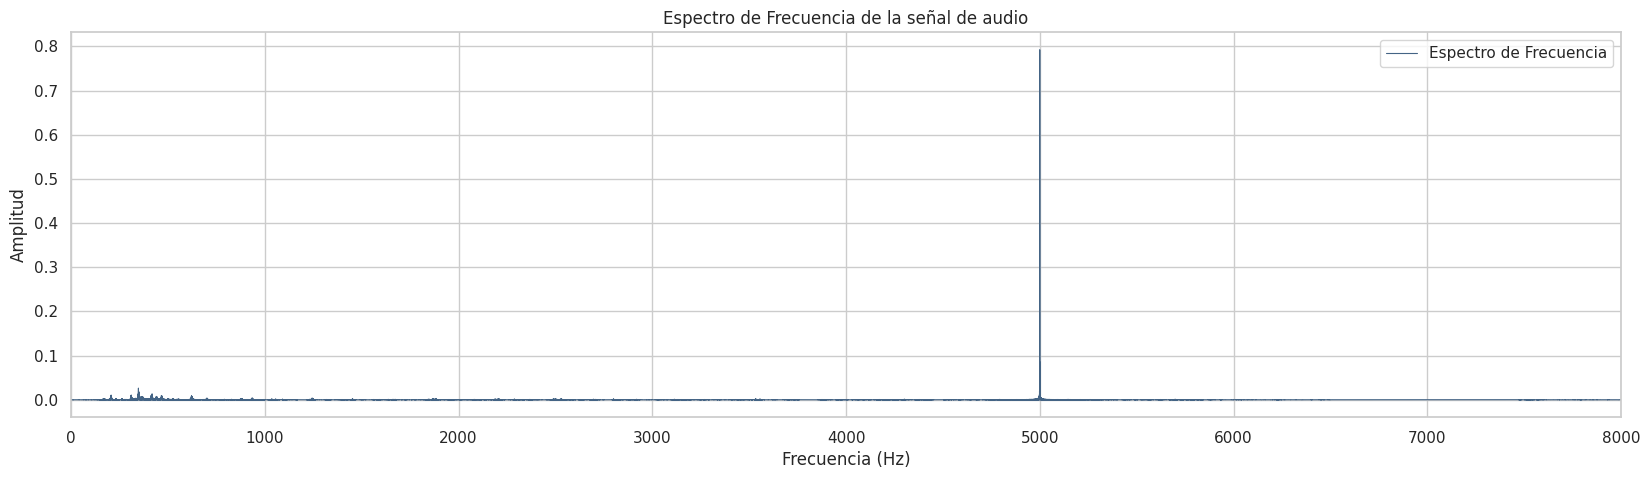

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import seaborn as sns
from scipy import fftpack
from IPython.display import Audio

sns.set(style="whitegrid")

def plot_signal(file_path):

    signal, sample_rate = librosa.load(file_path, sr=None)

    T = 1.0 / sample_rate
    N = len(signal)
    x = np.linspace(0.0, N*T, N)

    # Calculamos la trasnformada de Fourier y sus frecuencials
    yfb = fftpack.rfft(signal)
    yfb = 2.0 / N * np.abs(yfb[:int(N/2.0)])
    xfb = np.linspace(0.0, 1.0/(2.0*T), N//2)

    # Graficamos
    plt.figure(figsize=(20, 5))
    pal = sns.cubehelix_palette(6, rot=-0.25, light=0.7)
    plt.plot(xfb, yfb, label="Espectro de Frecuencia", color=pal[3], linewidth=0.8)

    plt.title("Espectro de Frecuencia de la señal de audio")
    plt.ylabel("Amplitud")
    plt.xlabel("Frecuencia (Hz)")
    plt.xlim(0, 8000)

    plt.legend()
    plt.show()

file_path = 'MA2.mp3'
plot_signal(file_path)
rec="MA2.mp3"
Audio(rec)


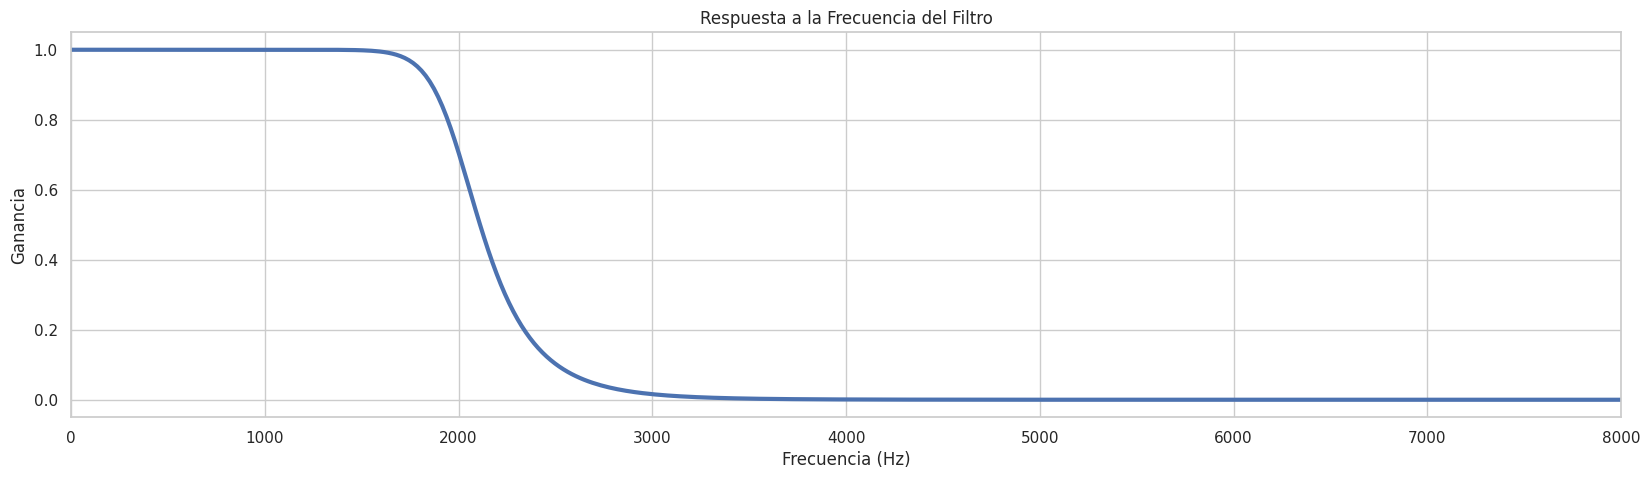

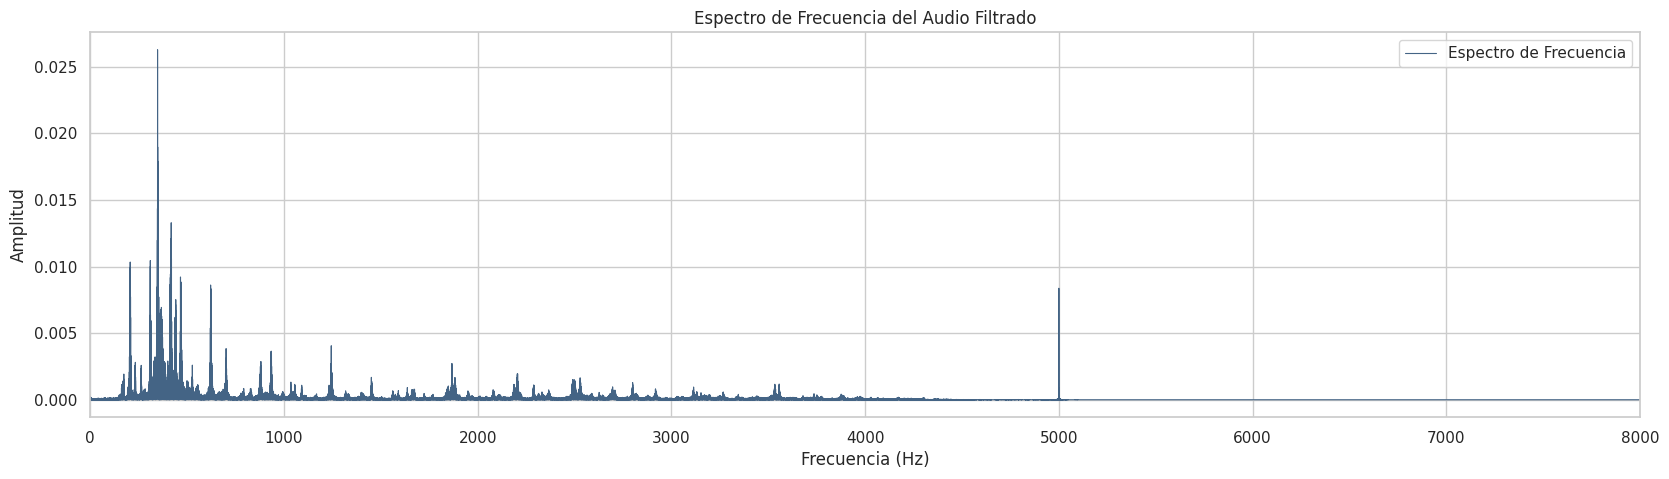

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt, freqz
from scipy import fftpack
import librosa
from IPython.display import Audio

sns.set(style="whitegrid")

def rad_sample_to_hz(x, fs):
    return (x * fs) / (2 * np.pi)

def plot_filter(b, a, fs):
    plt.figure(figsize=(20, 5))
    w, h = freqz(b, a, worN=512*2, whole=False)
    plt.plot(rad_sample_to_hz(w, fs), abs(h), linewidth=3)
    plt.title("Respuesta a la Frecuencia del Filtro")
    plt.ylabel("Ganancia")
    plt.xlabel("Frecuencia (Hz)")
    plt.xlim(0, 8000)
    plt.show()

def plot_signal(signal, sample_rate):
    plt.figure(figsize=(20, 5))
    pal = sns.cubehelix_palette(6, rot=-0.25, light=0.7)
    T = 1.0 / sample_rate
    N = len(signal)
    x = np.linspace(0.0, N*T, N)
    yfb = fftpack.rfft(signal)
    yfb = 2.0 / N * np.abs(yfb[:int(N/2.0)])
    xfb = np.linspace(0.0, 1.0/(2.0*T), N//2)
    plt.plot(xfb, yfb, label="Espectro de Frecuencia", color=pal[3], linewidth=0.8)
    plt.title("Espectro de Frecuencia del Audio Filtrado")
    plt.ylabel("Amplitud")
    plt.xlabel("Frecuencia (Hz)")
    plt.xlim(0, 8000)
    plt.legend()
    plt.show()

file_path = 'MA2.mp3'
rec, sample_rate = librosa.load(file_path, sr=None)

b, a = butter(10, 2000 / (0.5 * sample_rate), btype="low") #Filtro de Butterworth
filtered = filtfilt(b, a, rec)

plot_filter(b, a, sample_rate)
plot_signal(filtered, sample_rate)

Audio(filtered, rate=sample_rate)

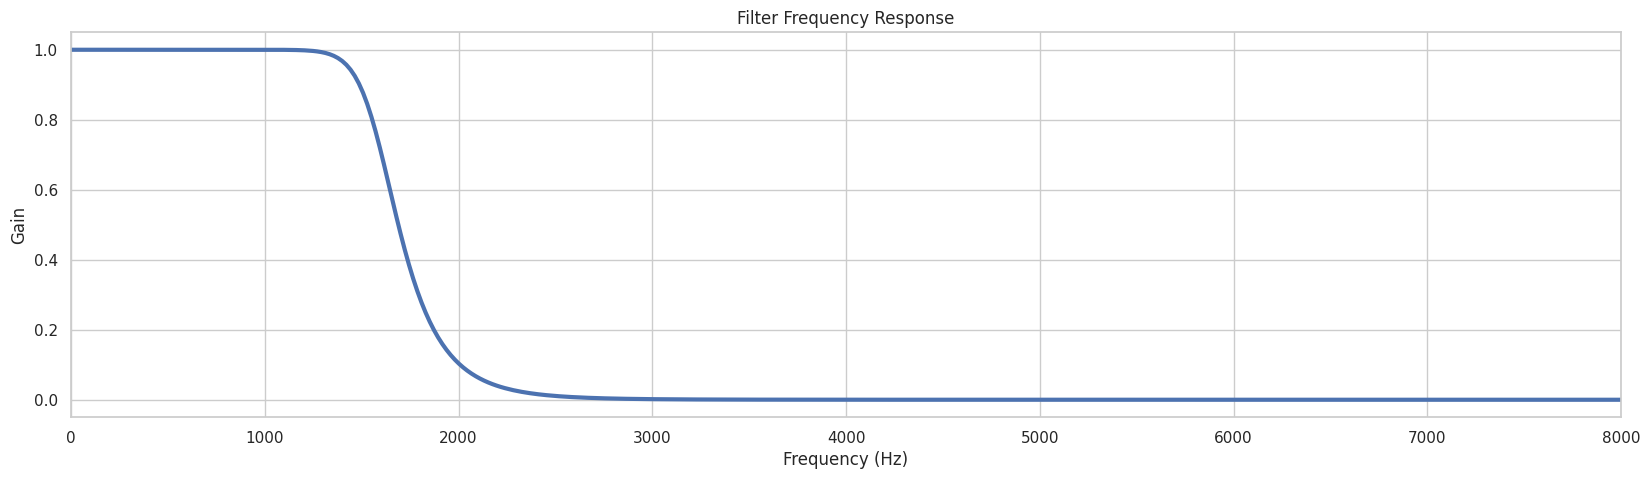

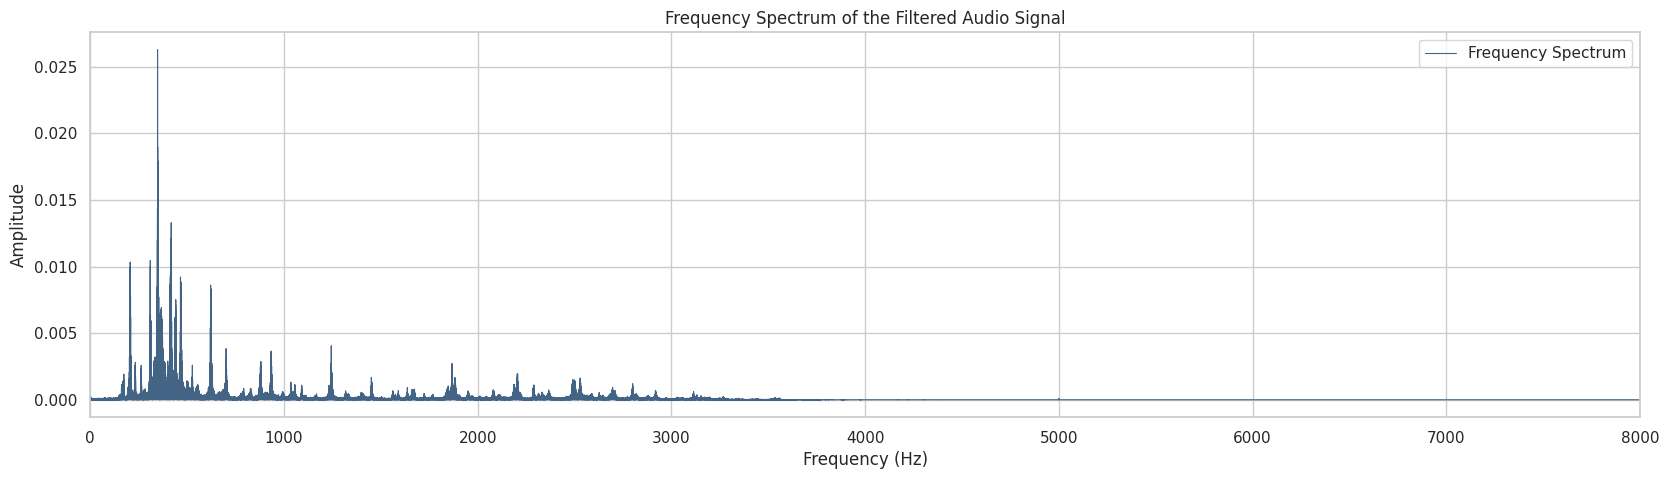

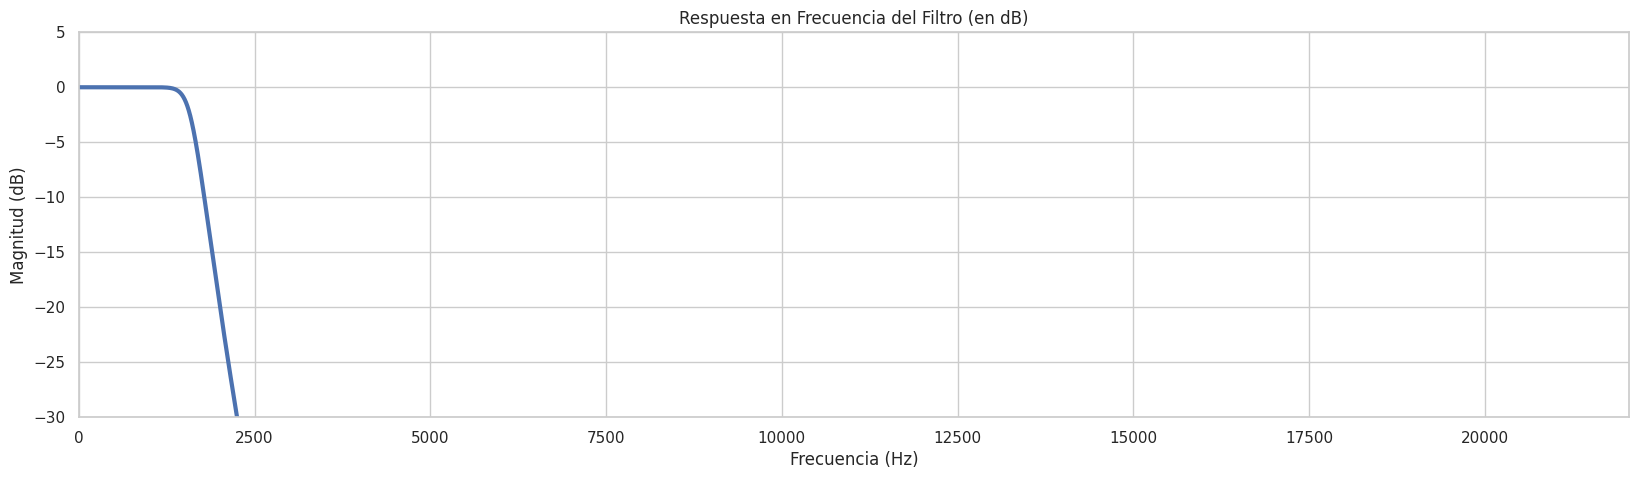

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt, freqz
from scipy import fftpack
import librosa
from IPython.display import Audio

sns.set(style="whitegrid")

def rad_sample_to_hz(x, fs):
    return (x * fs) / (2 * np.pi)

def plot_filter(b, a, fs):
    plt.figure(figsize=(20, 5))
    w, h = freqz(b, a, worN=512*2, whole=False)
    plt.plot(rad_sample_to_hz(w, fs), abs(h), linewidth=3)
    plt.title("Filter Frequency Response")
    plt.ylabel("Gain")
    plt.xlabel("Frequency (Hz)")
    plt.xlim(0, 8000)
    plt.show()

def plot_signal(signal, sample_rate):
    plt.figure(figsize=(20, 5))
    pal = sns.cubehelix_palette(6, rot=-0.25, light=0.7)
    T = 1.0 / sample_rate
    N = len(signal)
    x = np.linspace(0.0, N*T, N)
    yfb = fftpack.rfft(signal)
    yfb = 2.0 / N * np.abs(yfb[:int(N/2.0)])
    xfb = np.linspace(0.0, 1.0/(2.0*T), N//2)
    plt.plot(xfb, yfb, label="Frequency Spectrum", color=pal[3], linewidth=0.8)
    plt.title("Frequency Spectrum of the Filtered Audio Signal")
    plt.ylabel("Amplitude")
    plt.xlabel("Frequency (Hz)")
    plt.xlim(0, 8000)
    plt.legend()
    plt.show()


def plot_filter_in_db(b, a, fs):
    """Esta función grafica la respuesta en frecuencia de un filtro en decibeles."""
    plt.figure(figsize=(20, 5))
    w, h = freqz(b, a, worN=8000)
    # Convierte respuesta de frecuencia H(w) a decibeles
    h_db = 20 * np.log10(abs(h))

    # Convierte radianes por muestra a Hz
    f_hz = w * fs / (2 * np.pi)

    plt.plot(f_hz, h_db, linewidth=3)
    plt.title("Respuesta en Frecuencia del Filtro (en dB)")
    plt.ylabel("Magnitud (dB)")
    plt.xlabel("Frecuencia (Hz)")
    plt.xlim(0, fs / 2)  # Mostrar hasta la frecuencia de Nyquist
    plt.ylim(-30, 5)
    plt.grid(True)
    plt.show()

file_path = 'MA2.mp3'
rec, sample_rate = librosa.load(file_path, sr=None)

b, a = butter(10, 1600 / (0.5 * sample_rate), btype="low")
filtered = filtfilt(b, a, rec)

plot_filter(b, a, sample_rate)
plot_signal(filtered, sample_rate)
plot_filter_in_db(b, a, sample_rate)

Audio(filtered, rate=sample_rate)
